# pystackreg tutorial
This notebook demonstrates the uses of pystackreg on an example dataset of a live neuronal structure.

## Import pystackreg

In [1]:
import os
import sys
import numpy as np
from matplotlib import pyplot as plt
from skimage import transform, io, exposure

from pystackreg import StackReg
import pystackreg

In [2]:
print(pystackreg.__version__)

0.3.0.dev0


### Define helper functions

In [3]:
def overlay_images(imgs, equalize=False, aggregator=np.mean):
    
    if equalize:
        imgs = [exposure.equalize_hist(img) for img in imgs]
    
    imgs = np.stack(imgs, axis=0)
    
    return aggregator(imgs, axis=0)

In [4]:
def composite_images(imgs, equalize=False, aggregator=np.mean):
    
    if equalize:
        imgs = [exposure.equalize_hist(img) for img in imgs]
    
    imgs = [img / img.max() for img in imgs]
    
    if len(imgs) < 3:
        imgs += [np.zeros(shape=imgs[0].shape)] * (3-len(imgs))
  
    imgs = np.dstack(imgs)
    
    return imgs

### Load sample data

In [5]:
data_path = os.path.join(os.getcwd(), '..', 'data')
unreg = io.imread(os.path.join(data_path, 'pc12-unreg.tif'))

# convert to float to prevent overflows when calculating differences images
unreg = unreg.astype(float)

## Perform single image registration

In [6]:
transformations = {
    'TRANSLATION': StackReg.TRANSLATION,
    'RIGID_BODY': StackReg.RIGID_BODY,
    'SCALED_ROTATION': StackReg.SCALED_ROTATION,
    'AFFINE': StackReg.AFFINE,
    'BILINEAR': StackReg.BILINEAR
}

In [7]:
#load reference and "moved" image
ref = unreg[0, :, :]
mov = unreg[4, :, :]

### Show original images

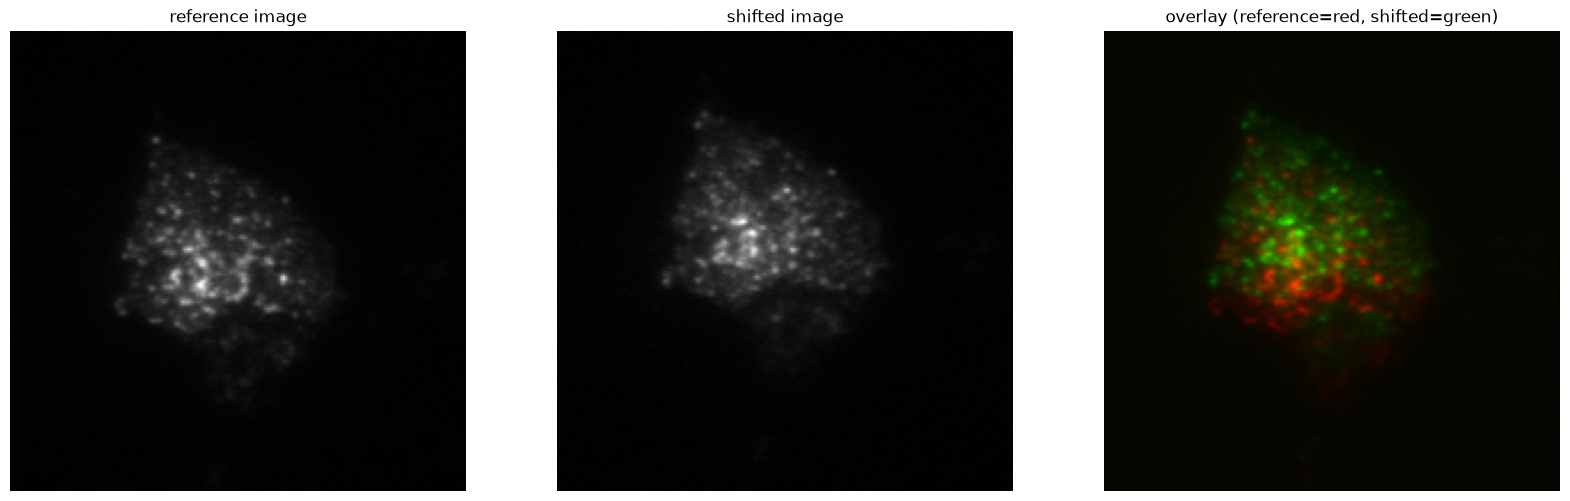

In [8]:
f, ax = plt.subplots(1, 3, figsize=(20, 9))

before_reg = composite_images([ref, mov])

ax[0].imshow(ref, cmap='gray')
ax[0].set_title('reference image')
ax[0].axis('off')

ax[1].imshow(mov, cmap='gray')
ax[1].set_title('shifted image')
ax[1].axis('off')

ax[2].imshow(before_reg)
ax[2].set_title('overlay (reference=red, shifted=green)')
ax[2].axis('off');

As can be seen from the overlay image (right), the second image (middle) is shifted considerably with respect to the reference image (left).

### Transform shifted image

We will next use all available transformation modes from pystackreg to register the shifted image to the reference image.

In [9]:
def show_transformation(tmat, ax=None):
    if ax is None:
        _, ax = plt.subplots()
    p = np.array([[1,120,1], [1,1,1], [250, 1, 1], [250,120,1], [1,120,1]])
    ax.plot(p[:, 0], p[:,1])
    q=np.dot(p, tmat.T)
    ax.plot(q[:, 0], q[:,1])
    ax.invert_xaxis()
    ax.invert_yaxis()
    ax.legend(['Original image', 'transformed image'])

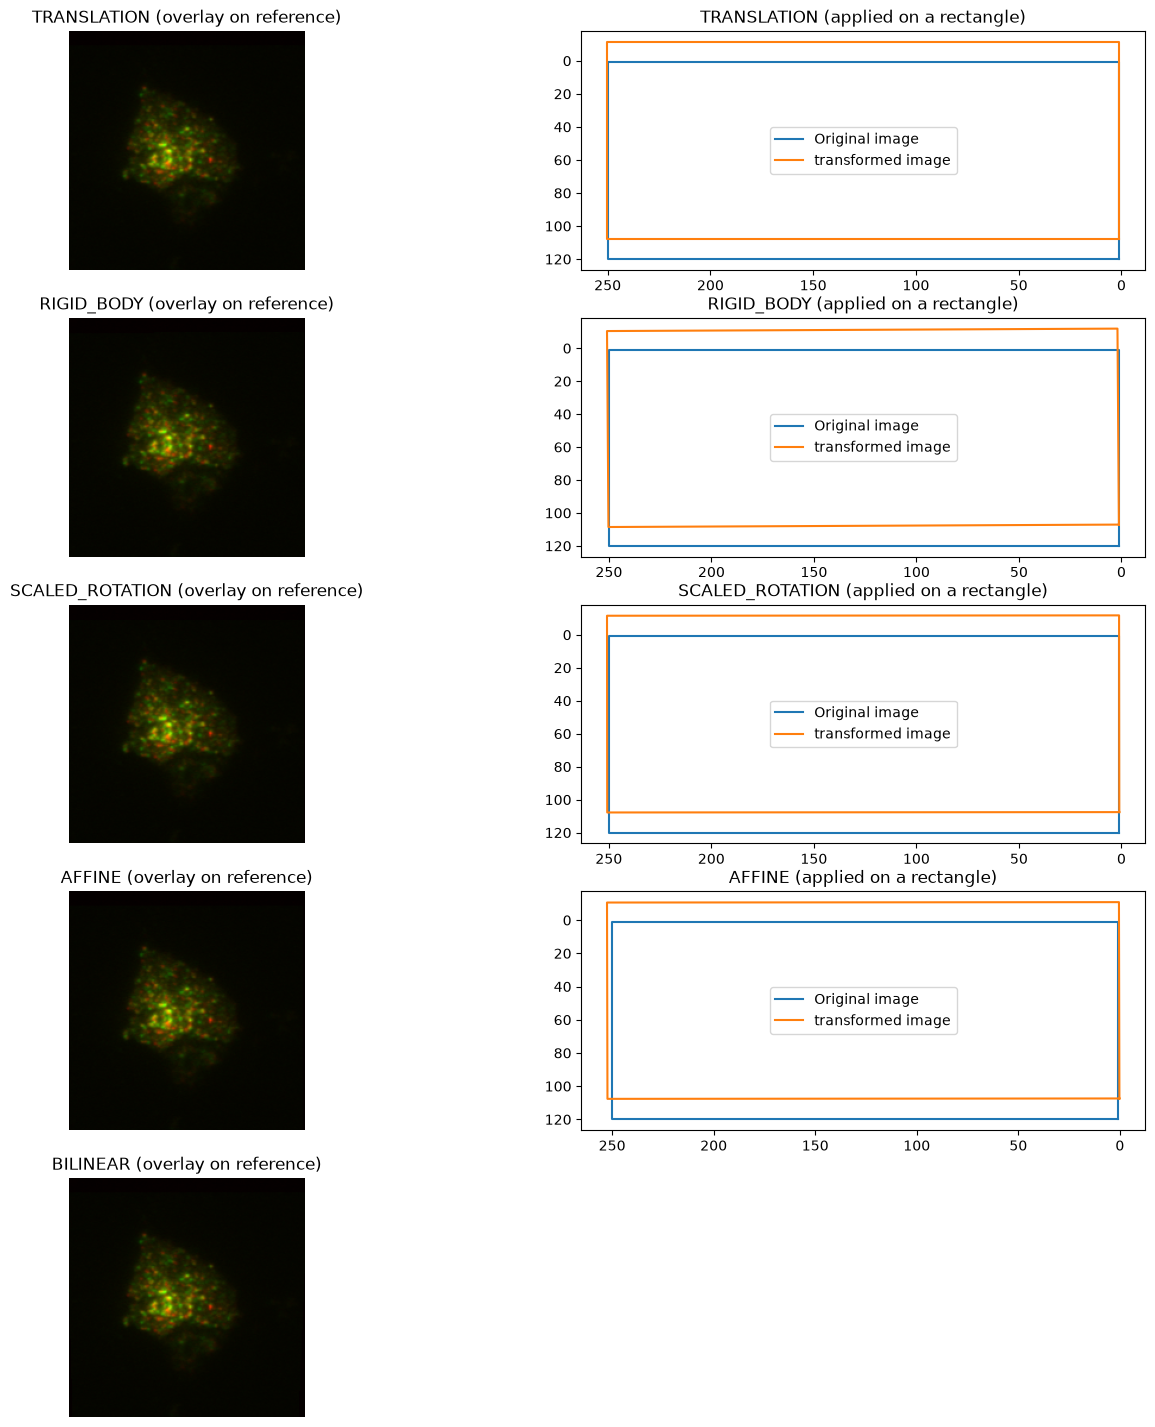

In [10]:
f, ax = plt.subplots(5, 2, figsize=(16, 18))

for i, (name, tf) in enumerate(transformations.items()):
    sr = StackReg(tf)
    reg = sr.register_transform(ref, mov)
    reg = reg.clip(min=0)
        
    after_reg =  composite_images([ref, reg])
    
    ax[i][0].imshow(after_reg, cmap='gray', vmin=0, vmax=1)
    ax[i][0].set_title(name + ' (overlay on reference)')
    ax[i][0].axis('off')
    
    if name != 'BILINEAR':
        show_transformation(sr.get_matrix(), ax[i][1])
        ax[i][1].set_title(name + ' (applied on a rectangle)')
    else:
        ax[i][1].axis('off')

Translation already performs a quite good job at registering the images.

In the right column, the action of the transformation matrix on a rectangle is shown.

## Perform stack transformations

In [11]:
print(f"Number of images in the stack: {len(unreg)}")

Number of images in the stack: 5


The original stack contains 5 images, we have so far only looked at the registration of two images out of that stack. We will next see how to use pystackreg to register the whole stack of 5 images.

### Show original images (overlay)

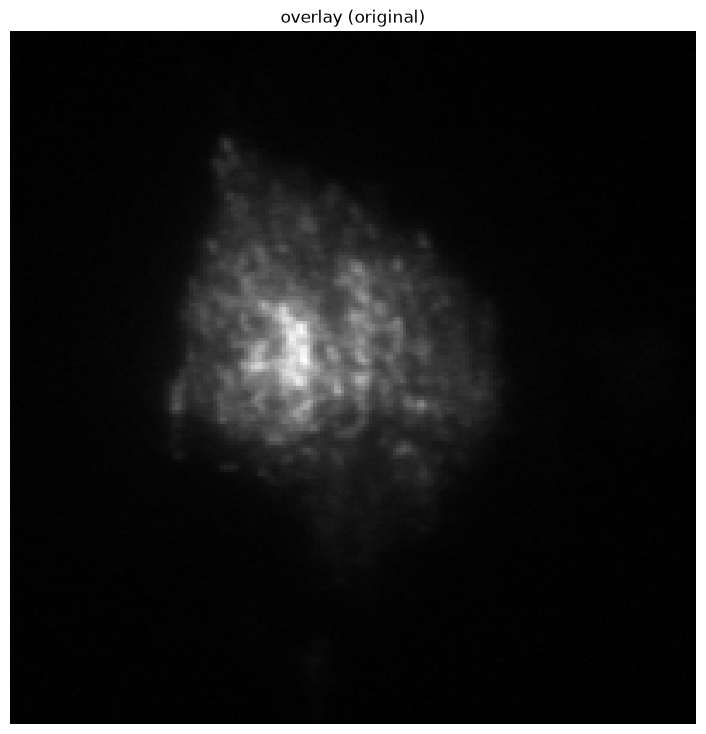

In [12]:
f, ax = plt.subplots(1, 1, figsize=(10, 9))

ax.imshow(overlay_images(unreg), cmap='gray')
ax.set_title('overlay (original)')
ax.axis('off');

The above image is the mean of each of the 5 images of the stack. As can bee seen, it is quite blurry due to the misalignment.

### Register and transform the whole stack

We will next use all 5 kinds of transformation offered by pystackreg to register the stack's images. Afterwards the average of the registered images is shown for each of the different types of transformations.

**Note** that we will save the transformation matrices of each transformation in a list `tmats` for later use.

For long stacks, pass `verbose=True` to show a progress bar (in a terminal or as a notebook widget).

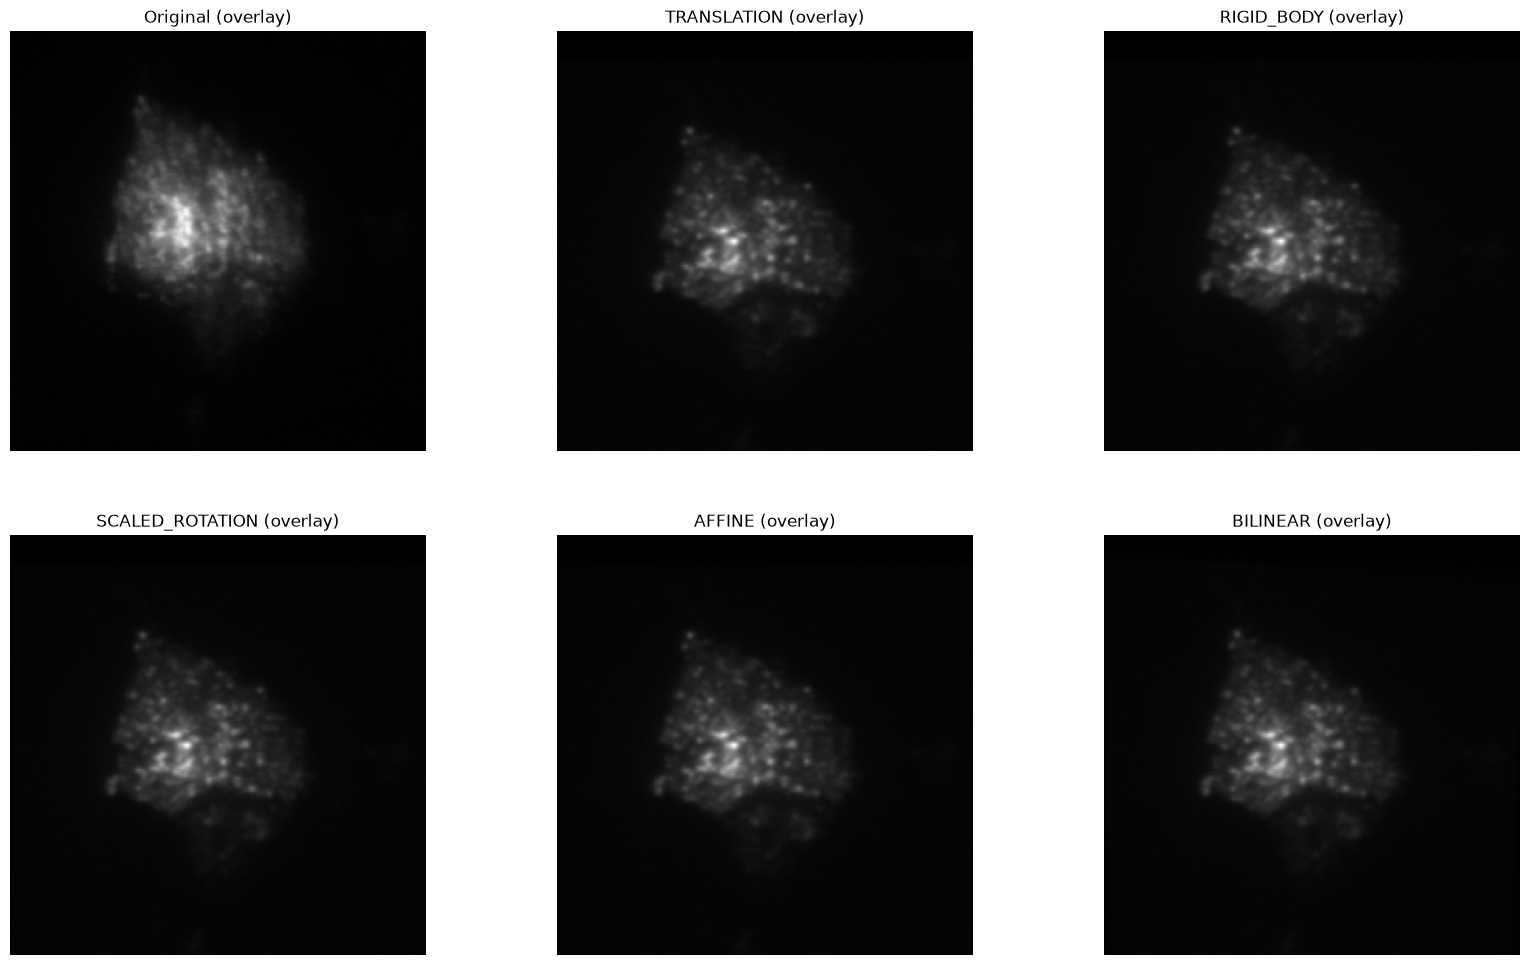

In [13]:
f, ax = plt.subplots(2, int(np.ceil((len(transformations)+1)/2)), figsize=(20, 12))
ax = ax.ravel()

ax[0].imshow(overlay_images(unreg, aggregator=np.mean), cmap='gray')
ax[0].set_title('Original (overlay)')
ax[0].axis('off')

# store transformation matrices for later use in this variable
tmats = []

for i, (name, tf) in enumerate(transformations.items()):
    sr = StackReg(tf)
    
    reference = 'first' if name == 'BILINEAR' else 'previous'
    
    tmat = sr.register_stack(unreg, axis=0, reference=reference)
    reg = sr.transform_stack(unreg)
    
    tmats.append(tmat)
    
    ax[i+1].imshow(overlay_images(reg, aggregator=np.mean), cmap='gray')
    ax[i+1].set_title(name + ' (overlay)')
    ax[i+1].axis('off')

As can bee seen, all types of transformation lead to a much clearer average image of the stack, equivalent to nicely registered images.

## Use saved transformation matrices

Note that in the above operation we have saved the transformation matrices generated from pystackreg in the variable `tmats`. We will now use the affine transformation implemented in skimage to perform  what pystackreg does in its `transform` functions using a different package. This will demonstrate that the transformation matrices supplied by pystackreg can be stored and used in any desired context even without having to use pystackreg.


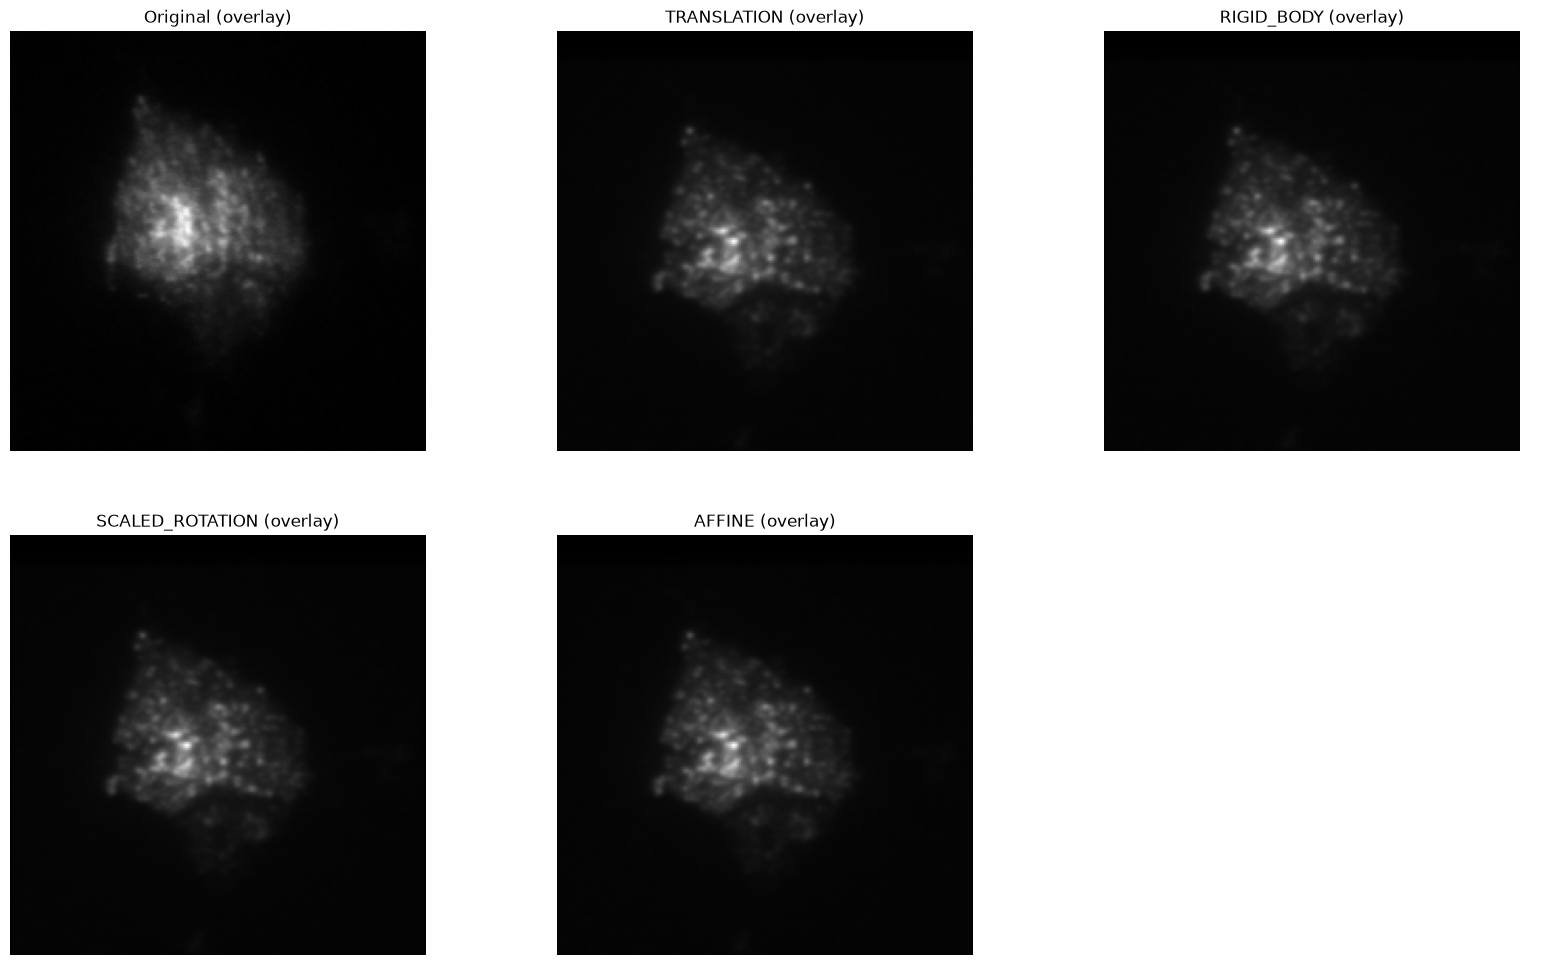

In [14]:
f, ax = plt.subplots(2, int(np.ceil((len(transformations)+1)/2)), figsize=(20, 12))
ax = ax.ravel()

ax[0].imshow(overlay_images(unreg, aggregator=np.mean), cmap='gray')
ax[0].set_title('Original (overlay)')
ax[0].axis('off')

for i, (name, tf) in enumerate(transformations.items()):
    
    if name == 'BILINEAR':
        # Bilinear transformation is not an affine transformation, we can't use the transformation matrix here
        continue
    
    # copy the unregistered image
    reg = unreg.copy()
    
    for i_img in range(unreg.shape[0]):
        # get skimage's AffineTransform object
        tform = transform.AffineTransform(matrix=tmats[i][i_img, :, :])
        
        # transform image using the saved transformation matrix
        reg[i_img, :, :] = transform.warp(reg[i_img, :, :], tform)
    
    
    ax[i+1].imshow(overlay_images(reg, aggregator=np.mean), cmap='gray')
    ax[i+1].set_title(name + ' (overlay)')
    ax[i+1].axis('off')

# turn off axis in remaining plots
for i in range(len(transformations), len(ax)):
    ax[i].axis('off')

## Custom callback for registration progress

The `register_stack()`, `transform_stack()` and `register_transform_stack()` functions can be called with a custom callback function that can be used to display progress information to the user. (Alternatively, `verbose=True` shows a progress bar.)

The custom callback needs to accept the two parameters `current_iteration` and `end_iteration`:

In [15]:
def show_progress(current_iteration, end_iteration):
    print(f"Registering {current_iteration} of {end_iteration} images")


sr = StackReg(StackReg.RIGID_BODY)
reg = sr.register_transform_stack(unreg, axis=0, progress_callback=show_progress)

Registering 1 of 4 images
Registering 2 of 4 images
Registering 3 of 4 images
Registering 4 of 4 images


## Clipping of negative values
The transformation output of pystackreg reproduces that of the ImageJ plugins TurboReg/StackReg on which it is based (see the validation notes in the documentation). Images are resampled with cubic spline interpolation, which can slightly over- and undershoot at sharp edges. The output of the transform function therefore has a `float` datatype and may contain negative values even if the input has none. To again create an image with integer values, the utility function `pystackreg.util.to_uint16()` can be used; alternatively, pass an integer array as `out` to `transform_stack()` (see below).

In [16]:
from pystackreg.util import to_uint16

In [17]:
sr = StackReg(StackReg.RIGID_BODY)
reg = sr.register_transform_stack(unreg - unreg.min())

print(f"The output of the transform function has the datatype {reg.dtype} with a minimal value of {reg.min()}")

The output of the transform function has the datatype float64 with a minimal value of -29.488252639770508


In [18]:
reg_int = to_uint16(reg)

print(f"After using the to_uint16 function, the output has a datatype {reg_int.dtype} with a minimal value of {reg_int.min()}")

After using the to_uint16 function, the output has a datatype uint16 with a minimal value of 0


## Registration of stacks having the frames/("time") not as the first axis
pystackreg expects the frames ("time") axis in a stacked image as the first axis, i.e. for a 3D numpy array, pystackreg expects the dimensions to be `frames x height x width`. pystackreg automatically tries to find out which axis is the frames axis and raises a warning if that axis is not the axis that the user supplied.

### Create test data

We will first create a stack that has the frames axis at axis 2 (instead of the default axis 0) by moving the axis from our sample data:

In [19]:
unreg.shape

(5, 201, 199)

In [20]:
unreg_axis = np.moveaxis(unreg, 0, 2)
unreg_axis.shape

(201, 199, 5)

### Register & transform
Next we register the stack using pystackreg's default parameters

In [21]:
import warnings

sr = StackReg(StackReg.RIGID_BODY)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    sr.register_stack(unreg_axis)

print(f"{caught[0].category.__name__}: {caught[0].message}")

Notice that this raises a warning as pystackreg correctly identified axis 2 as the frames axis. So let's use that axis for registration:

In [22]:
sr.register_stack(unreg_axis, axis=2);

Next transform the stack. Note that we need to supply the axis parameter again here - otherwise an error will be raised.

In [23]:
reg_axis = sr.transform_stack(unreg_axis, axis=2)

## Parallel processing
The frames of a stack can be registered and transformed by several threads at once with the `n_jobs` argument (`n_jobs=-1` uses all CPU cores). The results are identical to those of the sequential computation, for all reference modes: with `reference='previous'`, the pairwise registrations are computed in parallel and chained afterwards in frame order.

In [24]:
sr = StackReg(StackReg.RIGID_BODY)
tmats_sequential = sr.register_stack(unreg, reference='previous')
tmats_parallel = sr.register_stack(unreg, reference='previous', n_jobs=-1)

print(f"Parallel and sequential results are identical: {np.array_equal(tmats_sequential, tmats_parallel)}")

Parallel and sequential results are identical: True


## Memory-efficient processing of large stacks
By default, `transform_stack()` returns a new `float64` array, which for a 16-bit stack needs four times the memory of the input. The `out` argument writes the result into an existing array instead: an array of a smaller floating-point type, an integer array (values are rounded and clipped to the range of the data type), a memory-mapped file (`numpy.memmap`), or the input array itself to transform the stack in place.

In [25]:
stack16 = (unreg - unreg.min()).astype(np.uint16)

sr = StackReg(StackReg.RIGID_BODY)
sr.register_stack(stack16, reference='previous')

# 16-bit output: same size as the input
reg16 = np.empty_like(stack16)
sr.transform_stack(stack16, out=reg16)

# default output for comparison
reg64 = sr.transform_stack(stack16)

print(f"input: {stack16.nbytes / 1e6:.1f} MB ({stack16.dtype}), default output: {reg64.nbytes / 1e6:.1f} MB ({reg64.dtype}), "
      f"output with out=: {reg16.nbytes / 1e6:.1f} MB ({reg16.dtype})")
print(f"Integer output equals the rounded and clipped default output: {np.array_equal(reg16, to_uint16(reg64))}")

input: 0.4 MB (uint16), default output: 1.6 MB (float64), output with out=: 0.4 MB (uint16)
Integer output equals the rounded and clipped default output: True


For stacks that do not fit into memory, the input and output can be memory-mapped files, e.g. `np.load('stack.npy', mmap_mode='r+')`; frames are then read and written one at a time (per thread).

## Transforming point coordinates
The transformation matrices map coordinates `(x, y)` = `(column, row)` of the reference image onto coordinates of the unregistered image. `transform_points()` moves point coordinates in the same way as `transform()` moves the image content, i.e. it tells where a feature of the unregistered image is found after registration.

position before registration: [81. 83.], after registration: [80.61 95.45]


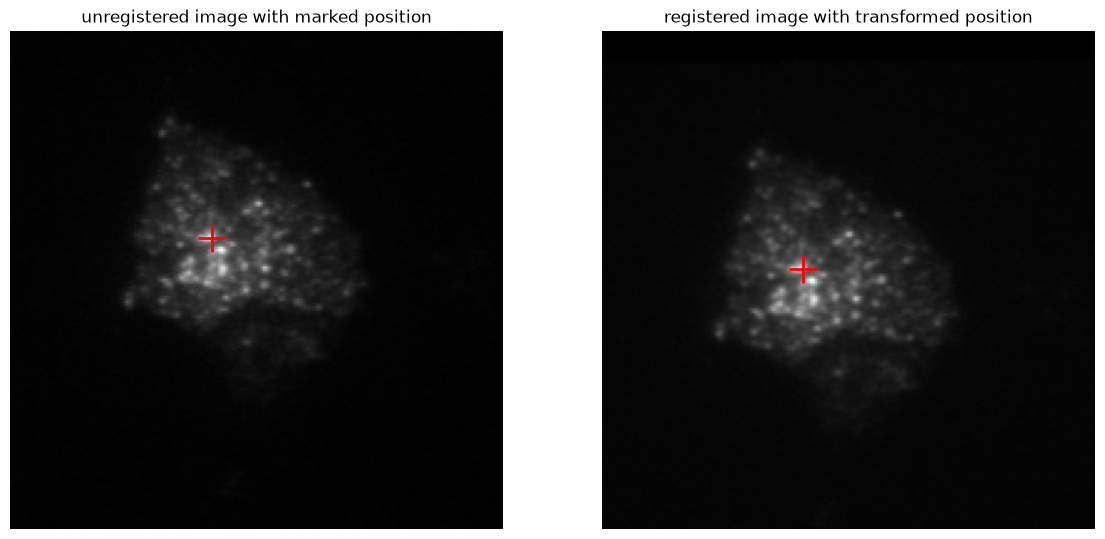

In [26]:
sr = StackReg(StackReg.RIGID_BODY)
tmat = sr.register(ref, mov)
reg = sr.transform(mov)

# position (x, y) of the brightest pixel in the unregistered image ...
y0, x0 = np.unravel_index(np.argmax(mov), mov.shape)
point = np.array([[x0, y0]], dtype=float)

# ... and where it is after registration
point_registered = sr.transform_points(point)

f, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(mov, cmap='gray')
ax[0].plot(*point[0], 'r+', markersize=20, markeredgewidth=2)
ax[0].set_title('unregistered image with marked position')
ax[0].axis('off')
ax[1].imshow(reg.clip(min=0), cmap='gray')
ax[1].plot(*point_registered[0], 'r+', markersize=20, markeredgewidth=2)
ax[1].set_title('registered image with transformed position')
ax[1].axis('off');

print(f"position before registration: {point[0]}, after registration: {point_registered[0].round(2)}")

## Checking the plausibility of a registration
The optimizer always returns a transformation, also if two images do not match. `pystackreg.util.max_displacement()` condenses a transformation matrix into a single number - the largest distance (in pixels) by which it moves any point of the image - which makes it easy to find frames whose registration looks implausible.

In [27]:
from pystackreg.util import max_displacement

sr = StackReg(StackReg.AFFINE)
tmats_affine = sr.register_stack(unreg, reference='first')

displacement = max_displacement(tmats_affine, unreg.shape[1:])
print("Largest displacement per frame (pixels):", displacement.round(1))

Largest displacement per frame (pixels): [ 0.   9.3 14.6 15.7 13.1]
